> **Copia para repositorio, sin reejecutar el EDA.** Solo se conservan salidas agregadas de las ejecuciones locales anteriores, fechadas en `docs/eda/README.md`. Se retiraron las demás salidas: microfotografías, captions completos, muestras y rutas personales. Se conserva el código de análisis. Configuración y protección de archivos adaptadas; reglas sin cambios. Los respaldos del historial permanecen locales. Una ejecución futura vuelve a producir resultados privados que no deben publicarse automáticamente.

# EDA de WBCAtt y sus imágenes PBC

Documento exploratorio reproducible; no constituye un dataset validado para entrenamiento. No modifica originales, particiones ni captions. No ejecuta notebooks antiguos ni analiza LeukemiaAttri.

**Procedencia:** el usuario confirmó que `Dataset/captions/captions.csv` fue extraído del ZIP proporcionado por Arturo. Se registra como **confirmación del usuario, no verificación independiente del contenido o autoría**.

**Corrección del inventario:** las primeras dos filas de captions son BA_100102.jpg y BA_101381.jpg, nombres diferentes. La afirmación anterior de que repetían nombre fue un error de redacción. Se conserva el inventario original; todos los resultados se calculan nuevamente aquí.

## Ejecución

Python 3 con `pandas numpy matplotlib Pillow nbformat nbclient ipykernel` (instalar mediante `python -m pip install` si hace falta). Configurar rutas abajo y ejecutar todas las celdas en orden. En Jupyter: Restart Kernel and Run All Cells. Las versiones quedan visibles. Los resultados completos se guardan en una sola base SQLite y tres PNG dentro de `resultados_wbcatt`; otras figuras quedan integradas aquí. La reejecución actualiza solo esos derivados. Las tablas visibles pueden ser muestras; SQLite conserva los registros completos.

Unidades distintas: **filas WBCAtt**, **archivos PBC**, **grupos de archivos iguales**, **filas de captions**, **textos distintos** y **comparaciones de atributos**.

## Registro de cambios — 2026-10-08

Se conserva la estructura de nueve secciones y el análisis de tablas, asociaciones y duplicados. Respaldo único previo: `01_EDA_WBCAtt.ipynb.bak`.

- Redondez nuclear separada de segmentación/lobulación; no se asigna una categoría completa a «round nucleus».
- Alcance explícito: cuatro de once atributos tienen reglas de comparación parcial; siete no se validan.
- Catálogo íntegro de textos por clase, frecuencia, reglas y límites de interpretación; pruebas controladas de las reglas.
- Advertencia histórica conservada y atribuida correctamente a recursos SQLite, con nueva inspección secuencial y conexiones cerradas explícitamente.
- Nota fechada añadida al inventario sin alterar su contenido histórico.
- Todas las celdas se vuelven a ejecutar; no se reutilizan resultados de inspección como si fueran nuevos. Las conclusiones se calculan a partir de las reglas actuales, sin exigir los conteos previos.


In [1]:
from pathlib import Path
import sys, hashlib, json, re, sqlite3, io, warnings, gc
from contextlib import closing
from html import escape
from datetime import datetime, timezone
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown, HTML
# RUTAS CONFIGURABLES
# Configurar HEMVLM_EDA_*; ver docs/eda/README.md.
HERE=Path.cwd().resolve()
REPO_ROOT=next((p for p in [HERE,*HERE.parents] if (p/'notebooks/eda/eda_paths.py').is_file()),None)
assert REPO_ROOT is not None, 'Iniciar desde el repositorio o notebooks/eda'
sys.path.insert(0,str(REPO_ROOT/'notebooks/eda'))
from eda_paths import eda_paths
EDA_PATHS=eda_paths()
DATASET_DIR=EDA_PATHS['dataset']
WBC_DIR=EDA_PATHS['wbcatt']
PBC_DIR=EDA_PATHS['pbc']
CAPTIONS_CSV=EDA_PATHS['captions']
OUTPUT_DIR=EDA_PATHS['output']/'resultados_wbcatt'
PARTITIONS=['train','val','test']; SEED=20261008; WORKERS=6
CSV_PATHS={s:WBC_DIR/f'pbc_attr_v1_{s}.csv' for s in PARTITIONS}
for p in [*CSV_PATHS.values(),CAPTIONS_CSV,PBC_DIR]:assert p.exists(),str(p)
assert OUTPUT_DIR.resolve() not in [WBC_DIR.resolve(),PBC_DIR.resolve(),CAPTIONS_CSV.parent.resolve()]
OUTPUT_DIR.mkdir(parents=True,exist_ok=True); DB=OUTPUT_DIR/'tablas_eda.sqlite'
display(pd.Series({'Python':sys.version,**{p:metadata.version(p) for p in ['pandas','numpy','matplotlib','Pillow','nbformat','nbclient','ipykernel']}},name='versión').to_frame())
print('UTC:',datetime.now(timezone.utc).isoformat()); print('Fuentes:',WBC_DIR,PBC_DIR,CAPTIONS_CSV,sep='\n')
plt.rcParams.update({'figure.dpi':110}); pd.set_option('display.max_colwidth',100)
def say(s):display(Markdown(s))
def save(name,df):
    with closing(sqlite3.connect(DB)) as con:df.to_sql(name,con,if_exists='replace',index=False)
def show(df,n=15):
    display(df.head(n))
    if len(df)>n:print(f'Muestra visible: {n} de {len(df)} filas; consultar la tabla completa en SQLite.')
def sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1048576),b''):h.update(block)
    return h.hexdigest()


,versión
Python,"3.14.6 | packaged by Anaconda, Inc. | (main, J..."
pandas,3.0.3
numpy,2.4.6
matplotlib,3.11.0
Pillow,12.3.0
nbformat,5.10.4
nbclient,0.11.0
ipykernel,6.31.0


## 1. Fuentes y estructura

**Pregunta:** ¿Qué representa cada fila y cómo se relacionan las fuentes? Leemos CSV completos como cadenas conservando vacíos y `nil`, sin asumir que este último sea un dato perdido. Se muestra el tipo inferido por pandas sin utilizarlo para transformar los originales. WBCAtt anota imágenes PBC; captions contiene textos de un universo más amplio y no se selecciona solo por su etiqueta de dataset.

In [ ]:
frames=[]; schemas=[]; sources=[]
for split,path in CSV_PATHS.items():
    d=pd.read_csv(path,dtype=str,keep_default_na=False); inferred=pd.read_csv(path,keep_default_na=False)
    schemas.extend({'partición':split,'columna':col,'tipo_conservado':str(d[col].dtype),'tipo_inferido':str(inferred[col].dtype)} for col in d)
    sources.append({'fuente':str(path),'sha256':sha(path),'filas':len(d),'columnas':len(d.columns)})
    d['split']=split; d['source_row']=np.arange(2,len(d)+2); frames.append(d)
    say(f'**{split}: {len(d):,} filas WBCAtt; primeras tres:**');display(d.head(3))
original=[x for x in frames[0] if x not in ['split','source_row']]
assert all([x for x in d if x not in ['split','source_row']]==original for d in frames)
w=pd.concat(frames,ignore_index=True);w.insert(0,'wbc_id',np.arange(len(w)))
attrs=[x for x in original if x not in ['img_name','label','path']]
cap=pd.read_csv(CAPTIONS_CSV,dtype=str,keep_default_na=False); cap_original=list(cap.columns)
sources.append({'fuente':str(CAPTIONS_CSV),'sha256':sha(CAPTIONS_CSV),'filas':len(cap),'columnas':len(cap.columns)})
cap.insert(0,'caption_id',np.arange(len(cap)));cap['source_row']=np.arange(2,len(cap)+2)
display(pd.DataFrame(schemas));display(pd.DataFrame(sources));save('fuentes',pd.DataFrame(sources));save('esquema',pd.DataFrame(schemas))
say(f'Hay **{len(w):,} filas WBCAtt**, **{len(attrs)} atributos** y **{len(cap):,} filas de captions en la fuente completa**. Los hashes identifican los CSV leídos; no demuestran procedencia histórica.')


## 2. Distribución de clases y atributos

**Pregunta:** ¿Qué clases y categorías están representadas? Contamos filas por clase/partición y por atributo/categoría/clase/partición. En los mapas de calor, cada porcentaje usa como denominador las filas de su clase. Conservamos todas las categorías literalmente. Son frecuencias de anotaciones, no prevalencias clínicas.

split,train,val,test,total
label,,,,
Basophil,744,125,349,1218
Eosinophil,1876,314,927,3117
Lymphocyte,736,111,367,1214
Monocyte,829,146,445,1420
Neutrophil,1984,334,1011,3329


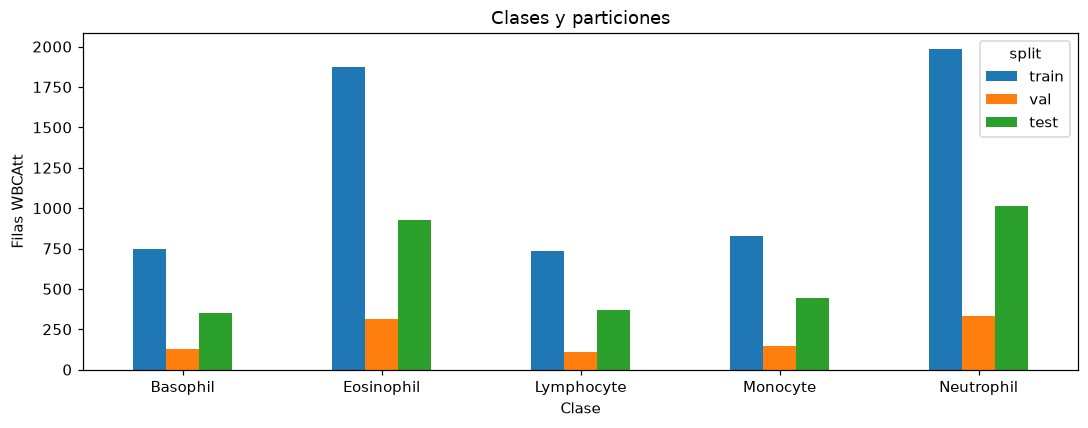

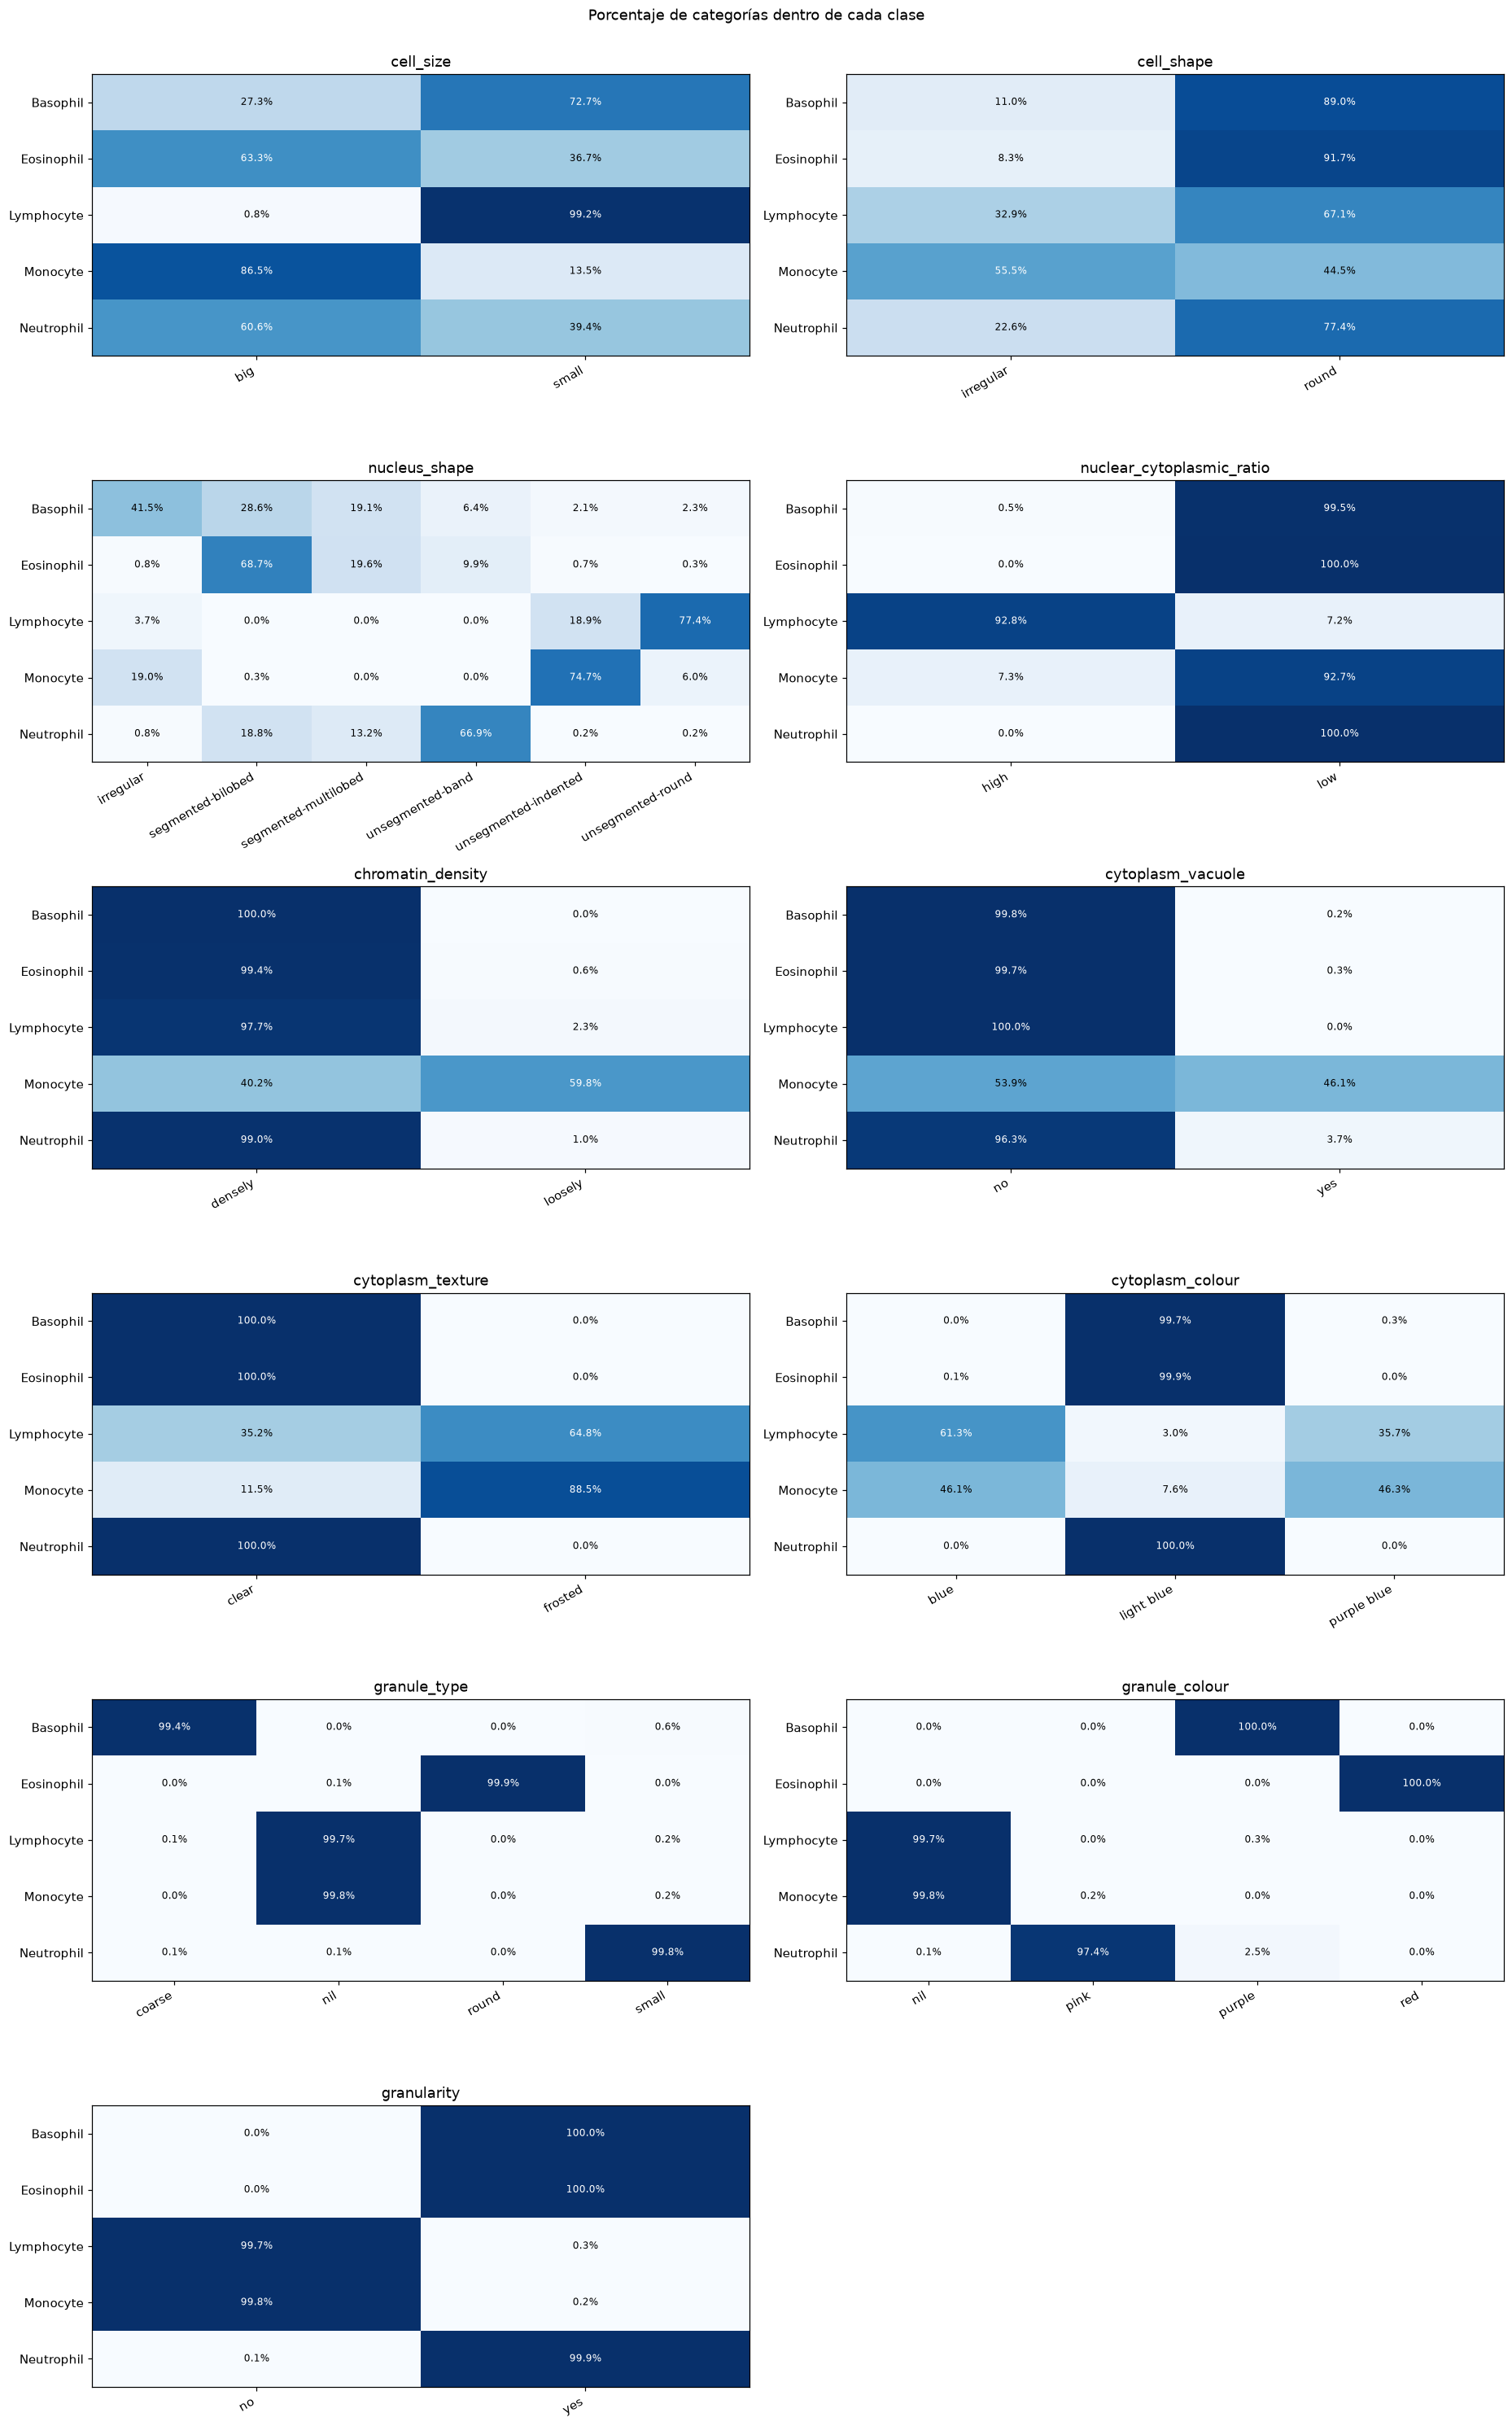

La clase más frecuente es **Neutrophil (3,329; 32.3%)** y la menos frecuente **Lymphocyte (1,214; 11.8%)**. La razón es 2.74. La concentración de atributos por clase puede facilitar aprender descripciones típicas, sin demostrar por sí sola errores de anotación.

In [3]:
dist=pd.crosstab(w.label,w.split).reindex(columns=PARTITIONS,fill_value=0);display(dist.assign(total=dist.sum(axis=1)));save('clases_particiones',dist.reset_index())
fig,ax=plt.subplots(figsize=(10,4));dist.plot.bar(ax=ax,rot=0);ax.set(ylabel='Filas WBCAtt',xlabel='Clase',title='Clases y particiones');fig.tight_layout();fig.savefig(OUTPUT_DIR/'01_clases.png');plt.show()
freq=[]
for a in attrs:
    f=w.groupby(['split','label',a],dropna=False).size().reset_index(name='filas').rename(columns={a:'categoria'});f['atributo']=a
    f['porcentaje_clase_particion']=100*f.filas/f.groupby(['split','label']).filas.transform('sum');freq.append(f)
freq=pd.concat(freq,ignore_index=True);save('atributos_frecuencias',freq)
fig,axes=plt.subplots(6,2,figsize=(17,27));axes=axes.ravel()
for ax,a in zip(axes,attrs):
    ct=pd.crosstab(w.label,w[a]);pct=100*ct.div(ct.sum(axis=1),axis=0)
    ax.imshow(pct,aspect='auto',vmin=0,vmax=100,cmap='Blues');ax.set_title(a)
    ax.set_xticks(range(len(pct.columns)),pct.columns,rotation=30,ha='right');ax.set_yticks(range(len(pct)),pct.index)
    for i in range(len(pct)):
        for j in range(len(pct.columns)):ax.text(j,i,f'{pct.iloc[i,j]:.1f}%',ha='center',va='center',fontsize=8,color='white' if pct.iloc[i,j]>55 else 'black')
for ax in axes[len(attrs):]:ax.axis('off')
fig.suptitle('Porcentaje de categorías dentro de cada clase',y=1.002);fig.tight_layout();fig.savefig(OUTPUT_DIR/'02_atributos.png',bbox_inches='tight');plt.show()
major=dist.sum(axis=1).sort_values(ascending=False)
say(f'La clase más frecuente es **{major.index[0]} ({major.iloc[0]:,}; {major.iloc[0]/len(w):.1%})** y la menos frecuente **{major.index[-1]} ({major.iloc[-1]:,}; {major.iloc[-1]/len(w):.1%})**. La razón es {major.iloc[0]/major.iloc[-1]:.2f}. La concentración de atributos por clase puede facilitar aprender descripciones típicas, sin demostrar por sí sola errores de anotación.')


## 3. Calidad de tablas

**Pregunta:** ¿Hay vacíos, variantes inconsistentes, filas repetidas o referencias compartidas entre particiones? Se cuentan espacios, valores vacíos y categorías que colapsarían al quitar espacios/cambiar mayúsculas, solo como diagnóstico. No se corrigen. Sin vocabulario oficial no se declara inválida una categoría por ser rara. Se distingue repetición de fila de repetición de nombre/ruta.

In [ ]:
quality=[];categories=[];variants=[]
for col in original:
    s=w[col];quality.append({'columna':col,'vacios':int(s.str.strip().eq('').sum()),'espacios_perifericos':int(s.ne(s.str.strip()).sum()),'distintos':s.nunique()})
    if col in ['label',*attrs]:
        categories.extend({'columna':col,'valor_literal':v,'filas':n} for v,n in s.value_counts().items())
        for key,g in s.groupby(s.str.strip().str.casefold()):
            if g.nunique()>1:variants.append({'columna':col,'clave':key,'variantes':json.dumps(sorted(g.unique()))})
quality=pd.DataFrame(quality);variants=pd.DataFrame(variants,columns=['columna','clave','variantes']);repeated=w[w.duplicated(original,keep=False)]
over=[]
for col in ['img_name','path']:
    for value,g in w.groupby(col):
        if len(g)>1:over.append({'campo':col,'valor':value,'filas':len(g),'particiones':','.join(sorted(g.split.unique())),'cruza_particiones':g.split.nunique()>1})
over=pd.DataFrame(over,columns=['campo','valor','filas','particiones','cruza_particiones'])
display(quality);display(variants);show(over)
for name,d in [('calidad',quality),('categorias_literales',pd.DataFrame(categories)),('variantes',variants),('filas_repetidas',repeated),('referencias_repetidas',over)]:save(name,d)
say(f'**{quality.vacios.sum()} celdas vacías**, **{len(variants)} grupos de variantes**, **{len(repeated)} filas participantes en duplicación exacta**, **{int(over.cruza_particiones.sum()) if len(over) else 0} referencias de nombre/ruta que cruzan particiones**. Nombre y ruta son diagnósticos separados, no imágenes adicionales. La ausencia de variantes no valida semánticamente el vocabulario; `nil` se conserva literalmente.')


## 4. Asociación exhaustiva WBCAtt–PBC

**Pregunta:** ¿Todas las filas llevan a un archivo inequívoco y qué PBC queda fuera? Indexamos todos los archivos de imagen de PBC. Se retira solo el prefijo conocido `PBC_dataset_normal_DIB/`, se exige coincidencia de nombre final con `img_name` y existencia de ruta relativa exacta. Un nombre único sin ruta verificada se conserva como candidato, sin aceptarlo. Una ruta puede resolver nombres compartidos; su cantidad de candidatos también queda registrada.

In [ ]:
paths=sorted(p for p in PBC_DIR.rglob('*') if p.is_file() and p.suffix.lower() in {'.jpg','.jpeg','.png','.tif','.tiff','.bmp','.webp'})
pbc=pd.DataFrame({'pbc_rel':[p.relative_to(PBC_DIR).as_posix() for p in paths]});pbc['filename']=pbc.pbc_rel.map(lambda s:Path(s).name);pbc['folder']=pbc.pbc_rel.str.split('/').str[0]
relset=set(pbc.pbc_rel);names=pbc.groupby('filename').pbc_rel.agg(list).to_dict()
def resolve(row):
    raw=row['path'].replace('\\','/');prefix='PBC_dataset_normal_DIB/';rel=raw[len(prefix):] if raw.startswith(prefix) else '';cand=names.get(row['img_name'],[])
    if not rel:status='prefijo_no_reconocido'
    elif Path(rel).name!=row['img_name']:status='conflicto_nombre_ruta'
    elif rel in relset:status='unica_verificada'
    elif len(cand)>1:status='ambigua_por_nombre'
    elif len(cand)==1:status='ruta_faltante_nombre_candidato'
    else:status='faltante'
    return pd.Series({'association':status,'pbc_rel':rel if status=='unica_verificada' else '', 'ruta_esperada':rel,'candidatos_nombre':json.dumps(cand),'n_candidatos_nombre':len(cand)})
w=pd.concat([w,w.apply(resolve,axis=1)],axis=1);referenced=set(w.loc[w.association.eq('unica_verificada'),'pbc_rel']);pbc['referenciada']=pbc.pbc_rel.isin(referenced)
coverage=pbc.groupby(['folder','referenciada']).size().unstack(fill_value=0).rename(columns={False:'fuera_WBCAtt',True:'en_WBCAtt'}).reset_index()
display(w.association.value_counts().rename_axis('asociación').to_frame('filas_WBCAtt'));display(coverage)
show(w.loc[w.association.ne('unica_verificada'),['wbc_id','split','img_name','path','association','candidatos_nombre']])
save('wbcatt_asociaciones',w);save('pbc_inventario',pbc);save('pbc_cobertura',coverage)
say(f'PBC tiene **{len(pbc):,} archivos**; **{len(referenced):,} archivos distintos** se asocian a **{int(w.association.eq("unica_verificada").sum()):,} filas WBCAtt**. **{len(pbc)-len(referenced):,} archivos quedan fuera**; no se excluyen de PBC ni se incorporan automáticamente a WBCAtt.')


## 5. Lectura, dimensiones, canales y ejemplos

**Pregunta:** ¿Son legibles las imágenes referenciadas? Decodificamos completamente **todos los archivos PBC**, mostrando por separado los referenciados. `load()` detecta fallos de lectura, no valida calidad clínica. Se registran dimensiones, modo, canales, errores y advertencias originales.

Calculamos SHA-256 de bytes y SHA-256 de píxeles **RGBA decodificados con dimensiones incluidas**. Convertir RGB a RGBA agrega alfa opaco; no se redimensiona ni aplica EXIF o corrección de color. Esta representación solo existe en memoria. Dos ejemplos completos por clase se seleccionan con semilla fija sobre rutas ordenadas; no son una evaluación visual exhaustiva.

**Interpretación de formatos:** dimensiones diferentes requerirían una transformación explícita si un modelo exige entrada de tamaño fijo. Este análisis conserva las dimensiones originales y no aplica esa transformación.

**Advertencia frente a error:** el registro previo vinculó una advertencia a `basophil/BA_101611.jpg`; su mensaje completo se conserva abajo como antecedente, no como resultado nuevo. Decía `unclosed database in <sqlite3.Connection ...>`: Python notificaba la recolección de una conexión SQLite que no se había cerrado explícitamente. `with sqlite3.connect(...)` gestiona transacciones pero no cierra la conexión. No era una advertencia del decodificador ni prueba de corrupción de esa imagen; la columna de error estaba vacía.

La captura anterior se realizaba con hilos y filtros de advertencias compartidos (`context_aware_warnings=0` en aquel entorno), por lo que la atribución por imagen no era fiable. Ahora se cierran explícitamente las conexiones y se inspecciona cada imagen secuencialmente, conservando categoría, módulo y línea de las advertencias nuevas. Una advertencia no equivale a una excepción de lectura. No se excluye ni modifica ningún archivo. Esta es una **nueva inspección completa**, no reutilización de la anterior.


In [ ]:
historical_warnings=[{'pbc_rel': 'basophil/BA_101611.jpg', 'error': '', 'advertencias': 'unclosed database in <sqlite3.Connection object at 0x0000023953B32F20> | unclosed database in <sqlite3.Connection object at 0x0000023953B335B0> | unclosed database in <sqlite3.Connection object at 0x0000023953B336A0>'}]
for prior in historical_warnings:
    say('**Antecedente de la ejecución previa (no inspección actual):**')
    print('Ruta registrada:',PBC_DIR/prior['pbc_rel'])
    print('Mensaje completo:',prior['advertencias'])
    print('Error de lectura registrado:',repr(prior['error']))
def inspect(rel):
    d={'pbc_rel':rel,'error':'','advertencias':'','advertencias_detalle':'[]'}; warns=[]
    try:
        raw=(PBC_DIR/rel).read_bytes();d['file_sha256']=hashlib.sha256(raw).hexdigest();d['bytes']=len(raw)
        with warnings.catch_warnings(record=True) as warns:
            warnings.simplefilter('always')
            with Image.open(io.BytesIO(raw)) as im:
                im.load();d.update(width=im.width,height=im.height,mode=im.mode,channels=len(im.getbands()),format=im.format)
                arr=np.asarray(im.convert('RGBA'),dtype=np.uint8);h=hashlib.sha256();h.update(f'RGBA|uint8|{im.width}|{im.height}|'.encode());h.update(arr.tobytes());d['pixel_sha256']=h.hexdigest()
    except Exception as e:d['error']=f'{type(e).__name__}: {e}'
    finally:
        d['advertencias']=' | '.join(str(x.message) for x in warns)
        d['advertencias_detalle']=json.dumps([{'categoria':x.category.__name__,'mensaje':str(x.message),'modulo':x.filename,'linea':x.lineno} for x in warns],ensure_ascii=False)
    return d
print(f'Decodificando {len(pbc):,} archivos...')
gc.collect()  # liberar recursos previos antes de atribuir advertencias a una imagen
info=pd.DataFrame([inspect(rel) for rel in pbc.pbc_rel])
info=info.merge(pbc,on='pbc_rel',validate='one_to_one')
for col in ['file_sha256','pixel_sha256','width','height','mode','channels','format']:
    if col not in info:info[col]=None
refinfo=info[info.referenciada];shapes=info.groupby(['referenciada','width','height','mode','channels'],dropna=False).size().reset_index(name='archivos')
display(shapes);show(info.loc[info.error.ne(''),['pbc_rel','referenciada','error']]);save('imagenes_inspeccion',info);save('imagenes_formatos',shapes)
say(f'Entre **{len(refinfo):,} archivos WBCAtt**, **{int(refinfo.error.ne("").sum())} errores** y **{int(refinfo.advertencias.ne("").sum())} archivos con advertencias**. Fuera de WBCAtt: **{int(info.loc[~info.referenciada,"error"].ne("").sum())} errores**. Las dimensiones/canales son resultados completos, no estimaciones por muestra.')
examples=[];classes=sorted(w.label.unique());fig,axes=plt.subplots(len(classes),2,figsize=(9,3.8*len(classes)),squeeze=False);readable=set(refinfo.loc[refinfo.error.eq(''),'pbc_rel'])
for i,label in enumerate(classes):
    candidates=w[w.label.eq(label)&w.pbc_rel.isin(readable)].drop_duplicates('pbc_rel').sort_values('pbc_rel');chosen=candidates.sample(min(2,len(candidates)),random_state=SEED)
    for ax,(_,row) in zip(axes[i],chosen.iterrows()):
        with Image.open(PBC_DIR/row.pbc_rel) as im:ax.imshow(im.copy())
        ax.set_title(f'{label} · {row["split"]}\n{row.img_name}');ax.axis('off');examples.append({'wbc_id':row.wbc_id,'label':label,'pbc_rel':row.pbc_rel,'semilla':SEED})
    for ax in axes[i][len(chosen):]:ax.axis('off')
fig.tight_layout();plt.show();save('ejemplos_visuales',pd.DataFrame(examples))

new_warnings=info.loc[info.advertencias.ne(''),['pbc_rel','referenciada','error','advertencias','advertencias_detalle']]
save('imagenes_advertencias_actuales',new_warnings)
for row in new_warnings.to_dict('records'):
    print('ADVERTENCIA ACTUAL - Ruta:',PBC_DIR/row['pbc_rel'])
    print('Mensaje completo:',row['advertencias']);print('Origen:',row['advertencias_detalle']);print('Error de lectura:',repr(row['error']))
if new_warnings.empty:say('**Inspección actual:** no se emitieron advertencias durante la lectura secuencial. El mensaje SQLite previo no se reprodujo y no se considera un defecto de imagen.')
for prior in historical_warnings:
    now=info.loc[info.pbc_rel.eq(prior['pbc_rel']),['pbc_rel','error','advertencias','width','height','mode']]
    say('**Resultado actual del archivo que figuraba en el antecedente:**');display(now)


## 6. Duplicados exactos y particiones

**Pregunta:** ¿archivos distintos representan la misma imagen y cruzan particiones? Igual SHA-256 de archivo indica igualdad de bytes salvo colisión criptográfica extremadamente improbable. Igual hash de píxeles exige misma matriz RGBA y tamaño, incluso si cambia codificación o metadatos. No se detectan duplicados aproximados ni vistas distintas de un paciente.

**No sumamos criterios:** componentes conectados unen las coincidencias y cada archivo pertenece a un solo grupo final. Se incluyen vínculos con PBC no referenciado. Los conflictos comparan clase y cada atributo entre filas WBCAtt del grupo, sin decidir cuál es correcta.

In [ ]:
parent={r:r for r in info.pbc_rel}
def find(x):
    while parent[x]!=x:parent[x]=parent[parent[x]];x=parent[x]
    return x
def union(a,b):
    a,b=find(a),find(b)
    if a!=b:parent[b]=a
criteria=[]
for criterion in ['file_sha256','pixel_sha256']:
    valid=info[info[criterion].notna()&info[criterion].ne('')];gs=[g for _,g in valid.groupby(criterion) if len(g)>1]
    criteria.append({'criterio':criterion,'grupos_PBC':len(gs),'archivos_PBC':sum(len(g) for g in gs),'grupos_con_2_o_mas_archivos_WBCAtt':sum(g.referenciada.sum()>1 for g in gs)})
    for g in gs:
        rr=g.pbc_rel.tolist()
        for other in rr[1:]:union(rr[0],other)
components=defaultdict(list)
for rel in parent:components[find(rel)].append(rel)
rows=[];members=[]
for rels in sorted(components.values(),key=lambda a:sorted(a)[0]):
    if len(rels)<2:continue
    gid=f'DUP_{len(rows)+1:04d}';ww=w[w.pbc_rel.isin(rels)];ii=info[info.pbc_rel.isin(rels)]
    fields=[a for a in ['label',*attrs] if ww[a].nunique(dropna=False)>1]
    rows.append({'grupo':gid,'archivos_PBC':len(rels),'archivos_WBCAtt':len(set(rels)&referenced),'filas_WBCAtt':len(ww),'particiones':','.join(sorted(ww.split.unique())),'cruza_particiones':ww.split.nunique()>1,'clases':','.join(sorted(ww.label.unique())),'conflicto_clase':ww.label.nunique()>1,'campos_conflictivos':','.join(fields),'hashes_archivo_distintos':ii.file_sha256.nunique(),'hashes_pixeles_distintos':ii.pixel_sha256.nunique()})
    members.extend({'grupo':gid,'pbc_rel':rel,'referenciada':rel in referenced} for rel in sorted(rels))
groups=pd.DataFrame(rows,columns=['grupo','archivos_PBC','archivos_WBCAtt','filas_WBCAtt','particiones','cruza_particiones','clases','conflicto_clase','campos_conflictivos','hashes_archivo_distintos','hashes_pixeles_distintos'])
members=pd.DataFrame(members,columns=['grupo','pbc_rel','referenciada']);same=[]
for rel,g in w[w.association.eq('unica_verificada')].groupby('pbc_rel'):
    if len(g)>1:same.append({'pbc_rel':rel,'filas':len(g),'cruza_particiones':g.split.nunique()>1,'campos_conflictivos':','.join(a for a in ['label',*attrs] if g[a].nunique()>1)})
same=pd.DataFrame(same,columns=['pbc_rel','filas','cruza_particiones','campos_conflictivos'])
cross=groups[groups.cruza_particiones.eq(True)];conflicts=groups[groups.campos_conflictivos.ne('')]
display(pd.DataFrame(criteria));show(groups,25);show(same)
for name,d in [('duplicados_criterios',pd.DataFrame(criteria)),('duplicados_grupos',groups),('duplicados_miembros',members),('misma_imagen_varias_filas',same)]:save(name,d)
say(f'**{len(groups)} grupos PBC unificados**, **{int(groups.archivos_WBCAtt.ge(2).sum())} con al menos dos archivos WBCAtt**, **{len(cross)} cruzan particiones** y **{len(conflicts)} tienen diferencias de clase/atributos**. No se suman los criterios. **No se descarta fuga por paciente:** no hay identificador validado en los CSV ni se infiere del nombre de archivo.')
if len(cross):say('**Cruces:**');display(cross)
if len(conflicts):say('**Conflictos candidatos:**');display(conflicts)


## 7. Captions: asociación, cobertura, textos y longitud

**Pregunta:** ¿Qué captions se asocian verificablemente a WBCAtt? Se exige prefijo `data/PBC_dataset_normal_DIB/PBC_dataset_normal_DIB/`, nombre final coherente con `filename`, ruta exacta existente y pertenencia a las imágenes verificadas WBCAtt. Etiqueta de dataset discrepante queda en diagnóstico. No seleccionamos por nombre aislado ni solo por dataset. Todas las filas no asociadas quedan en SQLite, incluidas otras fuentes, sin analizarlas aquí.

Medimos archivos cubiertos, filas de captions y textos literales distintos. Longitud en caracteres Unicode y palabras separadas por espacios, no tokens de modelo. **Compartir texto no hace duplicadas las imágenes.** Se usa el split original WBCAtt para estudiar textos entre particiones, conservando también el de Arturo.

In [ ]:
def resolve_cap(row):
    raw=row['image_path'].replace('\\','/');prefix='data/PBC_dataset_normal_DIB/PBC_dataset_normal_DIB/';rel=raw[len(prefix):] if raw.startswith(prefix) else ''
    if not rel:status='otra_fuente_o_prefijo_no_reconocido'
    elif Path(rel).name!=row['filename']:status='conflicto_nombre_ruta'
    elif rel not in relset:status='ruta_PBC_no_encontrada'
    elif row['dataset'].casefold()!='wbcatt':status='ruta_PBC_dataset_discrepante'
    elif rel in referenced:status='WBCAtt_verificado'
    else:status='PBC_fuera_WBCAtt'
    return pd.Series({'caption_association':status,'pbc_rel':rel,'candidatos_nombre_PBC':json.dumps(names.get(row['filename'],[]))})
cap=pd.concat([cap,cap.apply(resolve_cap,axis=1)],axis=1)
selected=cap[cap.caption_association.eq('WBCAtt_verificado')].copy();selected['caracteres']=selected.caption.str.len();selected['palabras']=selected.caption.str.split().str.len();selected['caption_vacio']=selected.caption.str.strip().eq('')
cc=selected.groupby('pbc_rel').agg(filas_captions=('caption_id','size'),textos_distintos=('caption','nunique')).reindex(sorted(referenced),fill_value=0).reset_index()
texts=selected.groupby('caption',dropna=False).agg(filas_captions=('caption_id','size'),archivos_PBC=('pbc_rel','nunique')).reset_index().sort_values('filas_captions',ascending=False)
pairs=selected.merge(w[['wbc_id','pbc_rel','split','label',*attrs]],on='pbc_rel',how='inner',suffixes=('_caption','_wbc'))
tc=pairs.groupby('caption').agg(particiones=('split_wbc',lambda x:','.join(sorted(set(x)))),n_particiones=('split_wbc','nunique'),archivos_PBC=('pbc_rel','nunique')).reset_index()
repeat_cap=selected[selected.duplicated(cap_original,keep=False)]
byclass=pairs.groupby('label').agg(filas_WBCAtt_con_caption=('wbc_id','nunique'),archivos_con_caption=('pbc_rel','nunique'),filas_captions=('caption_id','nunique'),textos_distintos=('caption','nunique')).reset_index()
display(cap.caption_association.value_counts().rename_axis('diagnóstico').to_frame('filas_captions'));display(byclass)
display(cc[['filas_captions','textos_distintos']].value_counts().rename('archivos_WBCAtt').reset_index());display(selected[['caracteres','palabras']].describe());say('Los textos completos, sin truncar y con reglas activadas, se presentan en la sección 8.')
for name,d in [('captions_diagnostico_completo',cap),('captions_WBCAtt',selected),('captions_cobertura_imagen',cc),('captions_cobertura_clase',byclass),('captions_textos',texts),('captions_textos_particiones',tc),('captions_filas_repetidas',repeat_cap)]:save(name,d)
fig,axes=plt.subplots(1,2,figsize=(11,4));selected.palabras.hist(ax=axes[0],bins=20);axes[0].set(xlabel='Palabras por caption',ylabel='Filas de captions',title='Longitud en WBCAtt');byclass.set_index('label').textos_distintos.plot.bar(ax=axes[1],rot=30);axes[1].set(ylabel='Textos literales distintos',xlabel='Clase',title='Diversidad textual');fig.tight_layout();fig.savefig(OUTPUT_DIR/'03_captions.png');plt.show()
say(f'**{len(selected):,} filas de captions**, **{selected.pbc_rel.nunique():,} archivos WBCAtt cubiertos**, **{selected.caption.nunique()} textos distintos**. **{int(cc.filas_captions.eq(0).sum())} archivos sin caption**, **{int(selected.caption_vacio.sum())} captions vacíos**, **{len(repeat_cap)} filas participantes en repetición completa**. **{int(texts.archivos_PBC.gt(1).sum())} textos compartidos entre archivos** y **{int(tc.n_particiones.gt(1).sum())} entre particiones**: repetición lingüística, no igualdad visual. Se conservaron **{len(cap)-len(selected):,} filas no seleccionadas**.')


## 8. Comparación semántica conservadora

**Pregunta:** ¿qué propiedades explícitas del texto pueden contrastarse con las anotaciones? **Solo cuatro de once atributos** tienen reglas capaces de producir coincidencias o contradicciones candidatas: `nucleus_shape`, `chromatin_density`, `granularity` y `cytoplasm_vacuole`. Las comparaciones de clase son adicionales y no cuentan como atributos morfológicos. Los otros siete atributos **no se validan**: se diagnostica si hay mención pertinente y si falta una regla para interpretarla.

**Corrección de round nucleus:** redondez, segmentación y lobulación son propiedades distintas. No se asigna `unsegmented-round` al texto. Con «round nucleus», el resultado de `nucleus_shape` es **incierto**, porque no se resuelve su categoría compuesta. Se guarda por separado `estado_propiedad`: solo `unsegmented-round` permite observar una coincidencia parcial de redondez; las otras etiquetas no se convierten automáticamente en «no redondo». Esa coincidencia parcial no se suma como una categoría validada. Si el núcleo está oculto o la expresión es mixta, también queda incierto.

La lobulación se contrasta solo entre los literales CSV que expresan explícitamente bilobulado o multilobulado. Frente a otras categorías se devuelve incierto, sin derivar un número de lóbulos por suposición. Esto también reduce el alcance de la regla anterior que comparaba categorías completas. Dense chromatin y dense coarse chromatin permiten comparar densidad; coarse/open/fine no se transforman en densely/loosely.

**Estados y motivos separados:**

- `coincidencia` y `contradiccion_candidata`: solo la propiedad explícita y documentada; no validan toda la célula ni deciden qué fuente es correcta.
- `omision`: no se detectó una mención pertinente del atributo. Se distingue `sin_mencion` de `referencia_otra_estructura` y `referencia_otra_propiedad`; no significa ausencia biológica.
- `incierto`: mención sin regla interpretable, categoría incompleta, código desconocido, expresión ambigua, negación o estructura no resuelta. `mencion_sin_regla` no se confunde con ausencia de mención.

Las negaciones (`no`, `not`, `without`, `absent`, `lacking`, `neither`, `nor`, `never`) y modalizadores se detectan conservadoramente: si aparecen en un texto con mención pertinente, no se emite veredicto de esa propiedad. No se resuelve su alcance sintáctico. Expresiones nucleares no se usan para tamaño/forma celular; vacuolas o gránulos atribuidos al núcleo no se comparan con presencia citoplasmática. Los detectores son heurísticos y parciales, sin sensibilidad/especificidad medida.

Abajo se presentan: tabla de alcance de los **11 atributos**, pruebas controladas, resultados recalculados y **todos los textos distintos, íntegros, agrupados por clase**, con frecuencia y reglas activadas. Los fragmentos de prueba no son captions nuevos ni se incorporan a ninguna fuente.


In [ ]:
class_names={x.casefold():x for x in w.label.unique()}
active={'nucleus_shape','chromatin_density','granularity','cytoplasm_vacuole'}
scope=[
 ('cell_size','Sin regla de comparación','Tamaño de la célula','Un núcleo o gránulo grande no implica célula grande.'),
 ('cell_shape','Sin regla de comparación','Contorno de la célula','Round nucleus describe núcleo, no célula.'),
 ('nucleus_shape','Lobulación explícita; redondez parcial sin adjudicar categoría','Bilobulado frente a multilobulado; redondez separada','Round siempre deja categoría incierta; no inferir segmentación; otras categorías sin número de lóbulos quedan inciertas.'),
 ('nuclear_cytoplasmic_ratio','Sin regla de comparación','Razón núcleo/citoplasma','Citoplasma escaso no permite asignar high/low.'),
 ('chromatin_density','Dense [coarse] chromatin frente a densely/loosely','Densidad explícita de cromatina','Coarse/open/fine sin dense no se interpretan como densidad.'),
 ('cytoplasm_vacuole','Vacuoles explícitas en contexto citoplasmático frente a yes/no','Presencia de vacuolas citoplasmáticas','Sin atribución citoplasmática, con referencia nuclear o negación: incierto.'),
 ('cytoplasm_texture','Sin regla de comparación','Textura citoplasmática','Mención genérica de citoplasma no especifica textura.'),
 ('cytoplasm_colour','Sin regla de comparación','Color citoplasmático','No trasladar colores del núcleo o gránulos al citoplasma.'),
 ('granule_type','Sin regla de comparación','Tipo/tamaño/forma de gránulos','Fine/coarse chromatin no describe los gránulos; no traducir nil.'),
 ('granule_colour','Sin regla de comparación','Color de gránulos','No traducir colores por aproximación ni interpretar nil.'),
 ('granularity','Granules/granular/granulation explícitos frente a yes/no','Presencia explícita de gránulos','Granulocyte no es evidencia de presencia; estructura nuclear o negación: incierto.')]
rules=pd.DataFrame(scope,columns=['atributo','regla','propiedad_comparada','limitaciones'])
rules['puede_comparar']=rules.atributo.isin(active)
assert len(rules)==11 and rules.puede_comparar.sum()==4
with pd.option_context('display.max_colwidth',None):display(HTML(rules.to_html(index=False,escape=True)))
save('captions_reglas',rules)
NEG=r'\b(no|not|without|absent|lacking|neither|nor|never)\b'
AMB=r'\b(may|might|possibly|perhaps|uncertain)\b|round to slightly irregular|horseshoe or kidney-shaped'
HIDDEN=r'\b(obscured|hidden|covered)\b'
GRAN=r'\b(granules|granular|granulation)\b'

def mention(text,a):
    t=text.casefold()
    # El valor devuelto distingue mención pertinente, otra estructura y ausencia.
    if a=='cell_size':
        m=re.search(r'\b(?:small|large|big) (?:cell|basophil|eosinophil|lymphocyte|monocyte|neutrophil)\b|\bcell size\b',t)
        other=re.search(r'\b(?:large|small|big)\b[^.;]{0,35}\b(?:nucleus|granules)\b',t)
    elif a=='cell_shape':
        m=re.search(r'\b(?:round|irregular) cell\b|\bcell shape\b',t)
        other=re.search(r'\b(?:round|irregular)\b[^.;]{0,30}\bnucleus\b',t)
    elif a=='nuclear_cytoplasmic_ratio':
        m=re.search(r'\bratio\b|nucleus.to.cytoplasm|nuclear.cytoplasmic ratio',t)
        other=re.search(r'\b(?:scant|minimal|abundant|plentiful)\b[^.;]{0,25}\bcytoplasm\b',t)
        if not m and other:return False,other.group(),'referencia_otra_propiedad'
    elif a=='cytoplasm_colour':
        m=re.search(r'\b(?:blue|gray-blue|purple|pale|light blue) cytoplasm\b|cytoplasm colo[u]?r',t)
        other=re.search(r'\b(?:dark|purple|reddish|red|pink)\b[^.;]{0,40}\b(?:granules|nucleus)\b',t)
    else:
        patterns={'nucleus_shape':r'\b(nucleus|nuclear)\b','chromatin_density':r'\bchromatin\b','cytoplasm_vacuole':r'\bvacuol\w*','cytoplasm_texture':r'\b(cytoplasm|cytoplasmic|texture)\b','granule_type':GRAN,'granule_colour':GRAN,'granularity':GRAN}
        m=re.search(patterns[a],t);other=None
    if m:return True,m.group(),'mencion_detectada'
    if other:return False,other.group(),'referencia_otra_estructura'
    return False,'','sin_mencion'

def compare(text,a,value):
    t=text.casefold();present,evidence,motive=mention(text,a)
    out={'estado':'incierto','evidencia':evidence,'regla':'sin_regla_interpretable','motivo':motive,'mencion_detectada':present,'regla_capaz_comparar':a in active,'propiedad_comparada':'','valor_texto_propiedad':'','valor_csv_propiedad':'','estado_propiedad':'incierto'}
    def result(status,rule,motive,prop='',tv='',cv='',pe=None,ev=None):
        out.update(estado=status,regla=rule,motivo=motive,propiedad_comparada=prop,valor_texto_propiedad=tv,valor_csv_propiedad=cv,estado_propiedad=pe if pe is not None else status)
        if ev is not None:out['evidencia']=ev
        return out
    if not present:return result('omision','sin_mencion_pertinente',motive)
    if a not in active:return result('incierto','sin_regla_de_comparacion','mencion_sin_regla')
    if re.search(NEG,t):return result('incierto','guardia_negacion','negacion_alcance_no_resuelto')
    if re.search(AMB,t):return result('incierto','guardia_ambiguedad','expresion_ambigua')
    if a=='nucleus_shape':
        if re.search(HIDDEN,t):return result('incierto','nucleo_oculto','observabilidad_limitada')
        if re.search(r'\bround nucleus\b',t):
            cv='redondo' if value=='unsegmented-round' else 'no_deducido'
            return result('incierto','redondez_sin_categoria','categoria_compuesta_no_resuelta','redondez','redondo',cv,'coincidencia' if cv=='redondo' else 'incierto','round nucleus')
        m=re.search(r'\b(bilobed|two-lobed|bilobular|multi-lobed|multi-lobulated) nucleus\b',t)
        if m:
            tv='bilobulado' if m.group(1) in ['bilobed','two-lobed','bilobular'] else 'multilobulado'
            cv={'segmented-bilobed':'bilobulado','segmented-multilobed':'multilobulado'}.get(value)
            if cv is None:return result('incierto','lobulacion_explicita','lobulacion_csv_no_resuelta','lobulacion',tv,'no_deducido',ev=m.group())
            return result('coincidencia' if tv==cv else 'contradiccion_candidata','lobulacion_explicita','propiedad_comparable','lobulacion',tv,cv,ev=m.group())
        return result('incierto','sin_regla_para_expresion_nuclear','mencion_sin_regla')
    if a=='chromatin_density':
        m=re.search(r'\bdense(?: coarse)? (?:nuclear )?chromatin\b',t)
        if not m:return result('incierto','sin_equivalencia_densidad','mencion_sin_regla')
        if value not in {'densely','loosely'}:return result('incierto','codigo_no_interpretado','codigo_desconocido')
        return result('coincidencia' if value=='densely' else 'contradiccion_candidata','densidad_explicita','propiedad_comparable','densidad_cromatina','densely',value,ev=m.group())
    if a=='cytoplasm_vacuole':
        if re.search(r'nuclear vacuoles|vacuoles[^.;]{0,20}\b(?:nucleus|nuclear)\b',t):return result('incierto','estructura_no_citoplasmatica','referencia_otra_estructura')
        m=re.search(r'\bcytoplasm[^.;]{0,40}\bvacuoles\b|\bcytoplasmic vacuoles\b|\bvacuoles in (?:the )?cytoplasm\b',t)
        if not m:return result('incierto','estructura_no_resuelta','mencion_sin_atribucion_citoplasmatica')
    else:
        if re.search(r'nuclear granules|granules[^.;]{0,20}\b(?:nucleus|nuclear)\b',t):return result('incierto','estructura_no_citoplasmatica','referencia_otra_estructura')
        m=re.search(GRAN,t)
    if value not in {'yes','no'}:return result('incierto','codigo_no_interpretado','codigo_desconocido')
    return result('coincidencia' if value=='yes' else 'contradiccion_candidata','presencia_explicita','propiedad_comparable',a,'yes',value,ev=m.group())

# Fragmentos controlados para verificar límites: no son nuevas filas de captions.
cases=[
 ('round nucleus','nucleus_shape','unsegmented-round','incierto','coincidencia'),
 ('round nucleus','nucleus_shape','segmented-bilobed','incierto','incierto'),
 ('round nucleus','nucleus_shape','irregular','incierto','incierto'),
 ('round nucleus','nucleus_shape','unsegmented-band','incierto','incierto'),
 ('round nucleus','nucleus_shape','codigo_desconocido','incierto','incierto'),
 ('round to slightly irregular nucleus','nucleus_shape','irregular','incierto','incierto'),
 ('round nucleus partially hidden by granules','nucleus_shape','unsegmented-round','incierto','incierto'),
 ('bilobed nucleus','nucleus_shape','segmented-bilobed','coincidencia','coincidencia'),
 ('bilobed nucleus','nucleus_shape','segmented-multilobed','contradiccion_candidata','contradiccion_candidata'),
 ('bilobed nucleus','nucleus_shape','unsegmented-band','incierto','incierto'),
 ('multi-lobed nucleus','nucleus_shape','segmented-bilobed','contradiccion_candidata','contradiccion_candidata'),
 ('dense chromatin','chromatin_density','loosely','contradiccion_candidata','contradiccion_candidata'),
 ('coarse chromatin','chromatin_density','densely','incierto','incierto'),
 ('dense granules','chromatin_density','densely','omision','omision'),
 ('no granules in cytoplasm','granularity','no','incierto','incierto'),
 ('granules in cytoplasm','granularity','no','contradiccion_candidata','contradiccion_candidata'),
 ('granules in nucleus','granularity','yes','incierto','incierto'),
 ('cytoplasm with fine vacuoles','cytoplasm_vacuole','no','contradiccion_candidata','contradiccion_candidata'),
 ('vacuoles in nucleus','cytoplasm_vacuole','yes','incierto','incierto'),
 ('large round nucleus','cell_size','big','omision','omision'),
 ('small lymphocyte','cell_size','small','incierto','incierto'),
 ('round nucleus','cell_shape','round','omision','omision')]
tested=[]
for text,a,value,expected,pe in cases:
    got=compare(text,a,value)
    assert got['estado']==expected and got['estado_propiedad']==pe,(text,a,got)
    tested.append({'fragmento':text,'atributo':a,'valor_csv':value,'esperado':expected,**got})
tests=pd.DataFrame(tested);save('captions_pruebas_reglas',tests)
say(f'**{len(tests)} comprobaciones controladas superadas.** La redondez no asigna segmentación ni una categoría completa.')
with pd.option_context('display.max_colwidth',None):display(HTML(tests[['fragmento','atributo','valor_csv','estado','estado_propiedad','motivo']].to_html(index=False)))

sem=[]
for r in pairs.to_dict('records'):
    base={'caption_id':r['caption_id'],'wbc_id':r['wbc_id'],'pbc_rel':r['pbc_rel'],'label':r['label'],'split':r['split_wbc'],'caption':r['caption']}
    meta=r['cell_type'].strip().casefold();status='omision' if not meta else ('incierto' if meta not in class_names else ('coincidencia' if class_names[meta]==r['label'] else 'contradiccion_candidata'))
    sem.append({**base,'campo':'cell_type_metadata','valor_csv':r['label'],'estado':status,'evidencia':r['cell_type'],'regla':'clase_literal','motivo':'clase_metadata'})
    found=[k for k in class_names if re.search(r'\b'+re.escape(k)+r'\b',r['caption'].casefold())]
    uncertain=bool(re.search(NEG+'|'+AMB,r['caption'].casefold()))
    status='omision' if not found else ('incierto' if len(found)!=1 or uncertain else ('coincidencia' if class_names[found[0]]==r['label'] else 'contradiccion_candidata'))
    sem.append({**base,'campo':'cell_type_texto','valor_csv':r['label'],'estado':status,'evidencia':','.join(found),'regla':'clase_textual','motivo':'clase_textual_con_guardias'})
    for a in attrs:sem.append({**base,'campo':a,'valor_csv':r[a],**compare(r['caption'],a,r[a])})
sem=pd.DataFrame(sem)
ss=pd.crosstab(sem.campo,sem.estado).reindex(columns=['coincidencia','contradiccion_candidata','omision','incierto'],fill_value=0);display(ss)
sc=sem.groupby(['label','campo','estado']).size().reset_index(name='comparaciones');bad=sem[sem.estado.eq('contradiccion_candidata')]
reasons=sem[sem.campo.isin(attrs)].groupby(['campo','motivo','estado']).size().reset_index(name='comparaciones')
save('captions_comparaciones',sem);save('captions_comparaciones_resumen',ss.reset_index());save('captions_comparaciones_clase',sc);save('captions_motivos',reasons)
assert not sem.loc[sem.campo.isin(set(attrs)-active),'estado'].isin(['coincidencia','contradiccion_candidata']).any()
assert sem.loc[sem.regla.eq('redondez_sin_categoria'),'estado'].eq('incierto').all()
say('**Ejemplos de contradicción candidata; textos íntegros:**')
with pd.option_context('display.max_colwidth',None):display(HTML(bad.groupby('campo',group_keys=False).head(2)[['caption_id','wbc_id','campo','valor_csv','propiedad_comparada','evidencia','caption']].to_html(index=False)))
say(f'**{len(bad):,} comparaciones candidatas**, **{bad.caption_id.nunique():,} filas de captions afectadas**, **{bad.pbc_rel.nunique():,} archivos**. Una imagen puede aportar varias comparaciones. Solo cuatro atributos tienen reglas de propiedades; los siete restantes no están validados.')

# Catálogo completo: los textos nunca se truncan ni se reemplazan por una muestra.
audit=[]
for (label,text),g in pairs.groupby(['label','caption'],sort=True):
    semantic_text=sem[sem.label.eq(label)&sem.caption.eq(text)&sem.campo.isin(attrs)]
    activated=semantic_text[semantic_text.campo.isin(active)][['campo','regla','propiedad_comparada','motivo']].drop_duplicates()
    details=[]
    for a in attrs:
        present,evidence,motive=mention(text,a)
        details.append({'atributo':a,'mencion':present,'evidencia':evidence,'motivo':motive,'capaz_comparar':a in active})
    neg=[m.group() for m in re.finditer(NEG,text.casefold())]
    amb=[m.group() for m in re.finditer(AMB+'|'+HIDDEN,text.casefold())]
    other=[f"{d['atributo']}: {d['evidencia']} ({d['motivo']})" for d in details if d['motivo'].startswith('referencia_otra')]
    lacks=semantic_text.loc[semantic_text.motivo.eq('mencion_sin_regla'),'campo'].unique().tolist()
    absent=[d['atributo'] for d in details if not d['mencion']]
    audit.append({'label':label,'caption':text,'filas_captions':g.caption_id.nunique(),'archivos_PBC':g.pbc_rel.nunique(),'reglas_activadas':json.dumps(activated.to_dict('records'),ensure_ascii=False),'sin_mencion_pertinente':', '.join(absent),'mencion_sin_regla':', '.join(sorted(lacks)),'negaciones':json.dumps(neg,ensure_ascii=False),'ambiguedades_ocultamiento':json.dumps(amb,ensure_ascii=False),'otras_estructuras_propiedades':json.dumps(other,ensure_ascii=False),'detalle_menciones':json.dumps(details,ensure_ascii=False)})
audit=pd.DataFrame(audit);save('captions_textos_auditados',audit)
assert audit.filas_captions.sum()==len(selected)
assert audit.caption.nunique()==selected.caption.nunique()
say(f'**Catálogo íntegro: {len(audit)} entradas clase/texto, {audit.caption.nunique()} textos distintos.** Ausencia de mención y falta de regla se muestran por separado. Los indicadores de negación/ambigüedad describen hallazgos textuales, no diagnósticos clínicos.')
for label,rows in audit.groupby('label',sort=True):
    say(f'### {label}')
    for i,row in enumerate(rows.to_dict('records'),1):
        say(f"**Texto {i} · {row['filas_captions']} filas de captions · {row['archivos_PBC']} archivos**")
        display(HTML('<p style="white-space:pre-wrap;overflow-wrap:anywhere">'+escape(row['caption'])+'</p>'))
        display(HTML(pd.DataFrame(json.loads(row['reglas_activadas'])).to_html(index=False,escape=True)))
        print('Sin mención pertinente:',row['sin_mencion_pertinente'] or 'ninguna')
        print('Mención pero sin regla interpretable:',row['mencion_sin_regla'] or 'ninguna')
        print('Negaciones detectadas:',row['negaciones'])
        print('Ambigüedad/ocultamiento:',row['ambiguedades_ocultamiento'])
        print('Referencia a otra estructura/propiedad:',row['otras_estructuras_propiedades'])
say('**Lectura del catálogo:** coarse/fine chromatin no se usa para tipo de gránulo; large round nucleus no se usa para tamaño celular; scant cytoplasm no se convierte en una razón núcleo/citoplasma. La clase mencionada no valida los atributos de cada imagen. Las guardias conservadoras pueden dejar sin interpretar expresiones válidas; requieren revisión humana.')


## 9. Conclusiones y propuestas, sin aplicar limpieza

**Pregunta:** ¿Qué se puede sostener y qué falta antes de entrenar? Esta síntesis usa solo resultados de la ejecución actual. Ninguna recomendación elimina datos o cambia particiones.

**Cómo consultar casos concretos:** en `resultados_wbcatt/tablas_eda.sqlite`, `duplicados_grupos` resume cada grupo y `duplicados_miembros` identifica sus archivos. Unir por `pbc_rel` con `wbcatt_asociaciones` permite recuperar filas, particiones y atributos originales. `captions_comparaciones` conserva cada evidencia textual, el `caption_id` y el `wbc_id`; `source_row` en las tablas de fuentes identifica la fila CSV (encabezado = fila 1). Los índices internos comienzan en cero.

Ejemplo desde Python, sin modificar la base:

```python
import sqlite3
import pandas as pd
with sqlite3.connect('file:resultados_wbcatt/tablas_eda.sqlite?mode=ro', uri=True) as con:
    con.execute('PRAGMA temp_store=MEMORY')
    conflictos = pd.read_sql_query(
        "SELECT * FROM duplicados_grupos WHERE campos_conflictivos <> ''", con)
```

El notebook es el documento principal; las tablas completas permiten revisar los casos sin producir múltiples CSV auxiliares.

In [10]:
summary={'filas_WBCAtt':len(w),'archivos_PBC':len(pbc),'archivos_PBC_referenciados':len(referenced),'archivos_PBC_fuera_WBCAtt':len(pbc)-len(referenced),'filas_asociacion_no_verificada':int(w.association.ne('unica_verificada').sum()),'errores_lectura_referenciadas':int(refinfo.error.ne('').sum()),'celdas_vacias_WBCAtt':int(quality.vacios.sum()),'filas_WBCAtt_repetidas_participantes':len(repeated),'grupos_duplicados_PBC_unificados':len(groups),'grupos_cruzan_particiones':len(cross),'grupos_conflicto_anotaciones':len(conflicts),'filas_captions_fuente':len(cap),'filas_captions_WBCAtt':len(selected),'archivos_WBCAtt_con_caption':selected.pbc_rel.nunique(),'textos_distintos_WBCAtt':selected.caption.nunique(),'comparaciones_contradiccion_candidata':len(bad),'archivos_con_contradiccion_candidata':bad.pbc_rel.nunique(),'atributos_con_regla_comparativa':len(active),'atributos_sin_regla_comparativa':len(attrs)-len(active),'archivos_con_advertencia_actual':len(new_warnings)}
sumdf=pd.Series(summary,name='resultado').rename_axis('medida').reset_index();display(sumdf);save('resumen',sumdf)
say(f"""**Hallazgos.** {len(w):,} filas WBCAtt de {w.label.nunique()} clases se asocian a {len(referenced):,} archivos de los {len(pbc):,} archivos PBC. Quedan {len(pbc)-len(referenced):,} fuera de WBCAtt. La clase más frecuente aporta {major.iloc[0]/len(w):.1%}. Hubo {int(refinfo.error.ne('').sum())} errores de lectura referenciada.

**Advertencias.** La nueva inspección secuencial produjo {len(new_warnings)} archivos con advertencias. El antecedente de BA_101611.jpg era un aviso de conexión SQLite sin cerrar, no un error de decodificación ni evidencia de corrupción. El mensaje completo y la comprobación actual están en la sección 5.

**Duplicados.** {len(groups)} grupos PBC unificados por bytes/píxeles; {len(cross)} cruzan particiones WBCAtt y {len(conflicts)} tienen diferencias de anotaciones. No sumar criterios ni declarar descartada fuga por paciente o similitud aproximada.

**Captions.** {len(selected):,} filas cubren {selected.pbc_rel.nunique():,} archivos y usan {selected.caption.nunique()} textos distintos. La repetición limita diversidad y puede facilitar memorizar patrones de clase. Solo cuatro atributos cuentan con reglas comparativas parciales; los siete restantes no se validaron. Round nucleus queda incierto a nivel de categoría, sin asignar unsegmented-round. Hay contradicciones candidatas en {bad.pbc_rel.nunique():,} archivos según reglas parciales, sin decidir qué fuente tiene razón.

**Propuestas futuras:** documentar rutas y vocabulario; revisar visualmente grupos duplicados y conflictos antes de decidir una política común entre particiones; revisar captions candidatos y una muestra de coincidencias/omisiones/incertidumbres; investigar identificadores por paciente; distinguir descripciones típicas de observaciones específicas. No se aplicó ninguna exclusión ni corrección.

**Limitaciones:** no hay validación clínica, detección de duplicados aproximados ni identificadores de paciente verificados. Los hashes solo detectan igualdad exacta. Solo cuatro de once atributos tienen reglas capaces de comparar propiedades; los otros siete no se validaron. Las reglas son parciales, sin sensibilidad/especificidad medida; no se interpretan códigos, colores o tamaños por suposición. Los captions fuera de WBCAtt se conservan sin EDA de LeukemiaAttri. La procedencia Arturo es confirmación del usuario. **No es un dataset final validado para entrenamiento.**""")
assert len(w)==sum(len(d) for d in frames)
assert len(pbc)==len(info)==info.pbc_rel.nunique()
assert len(cap)==cap.caption_id.nunique()
assert len(sem)==len(pairs)*(len(attrs)+2)
assert cc.filas_captions.sum()==len(selected)
assert members.pbc_rel.nunique()==len(members)
for source in sources:assert sha(source['fuente'])==source['sha256'],'CSV modificado durante ejecución'
with closing(sqlite3.connect(DB)) as con:
    assert con.execute('PRAGMA integrity_check').fetchone()[0]=='ok'
    tables=pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name",con)
say('**Verificaciones:** conteos coherentes, hashes de los cuatro CSV sin cambios durante ejecución y SQLite íntegra. No se escribió en fuentes. Contenido previo del inventario conservado; nota de corrección añadida el 2026-10-08.')
display(tables);print('Resultados:',OUTPUT_DIR);print('Consulta: SELECT * FROM resumen;')

assert len(active)==4 and len(set(attrs)-active)==7
assert len(tests)>0 and audit.caption.nunique()==selected.caption.nunique()
assert not sem.loc[sem.campo.isin(set(attrs)-active),'estado'].isin(['coincidencia','contradiccion_candidata']).any()
print('Reglas comprobadas; catálogo completo; siete atributos sin adjudicación semántica.')


,medida,resultado
0,filas_WBCAtt,10298
1,archivos_PBC,17092
2,archivos_PBC_referenciados,10298
3,archivos_PBC_fuera_WBCAtt,6794
4,filas_asociacion_no_verificada,0
5,errores_lectura_referenciadas,0
6,celdas_vacias_WBCAtt,0
7,filas_WBCAtt_repetidas_participantes,0
8,grupos_duplicados_PBC_unificados,17
9,grupos_cruzan_particiones,6


**Hallazgos.** 10,298 filas WBCAtt de 5 clases se asocian a 10,298 archivos de los 17,092 archivos PBC. Quedan 6,794 fuera de WBCAtt. La clase más frecuente aporta 32.3%. Hubo 0 errores de lectura referenciada.

**Advertencias.** La nueva inspección secuencial produjo 0 archivos con advertencias. El antecedente de BA_101611.jpg era un aviso de conexión SQLite sin cerrar, no un error de decodificación ni evidencia de corrupción. El mensaje completo y la comprobación actual están en la sección 5.

**Duplicados.** 17 grupos PBC unificados por bytes/píxeles; 6 cruzan particiones WBCAtt y 5 tienen diferencias de anotaciones. No sumar criterios ni declarar descartada fuga por paciente o similitud aproximada.

**Captions.** 10,298 filas cubren 10,298 archivos y usan 25 textos distintos. La repetición limita diversidad y puede facilitar memorizar patrones de clase. Solo cuatro atributos cuentan con reglas comparativas parciales; los siete restantes no se validaron. Round nucleus queda incierto a nivel de categoría, sin asignar unsegmented-round. Hay contradicciones candidatas en 1,261 archivos según reglas parciales, sin decidir qué fuente tiene razón.

**Propuestas futuras:** documentar rutas y vocabulario; revisar visualmente grupos duplicados y conflictos antes de decidir una política común entre particiones; revisar captions candidatos y una muestra de coincidencias/omisiones/incertidumbres; investigar identificadores por paciente; distinguir descripciones típicas de observaciones específicas. No se aplicó ninguna exclusión ni corrección.

**Limitaciones:** no hay validación clínica, detección de duplicados aproximados ni identificadores de paciente verificados. Los hashes solo detectan igualdad exacta. Solo cuatro de once atributos tienen reglas capaces de comparar propiedades; los otros siete no se validaron. Las reglas son parciales, sin sensibilidad/especificidad medida; no se interpretan códigos, colores o tamaños por suposición. Los captions fuera de WBCAtt se conservan sin EDA de LeukemiaAttri. La procedencia Arturo es confirmación del usuario. **No es un dataset final validado para entrenamiento.**

**Verificaciones:** conteos coherentes, hashes de los cuatro CSV sin cambios durante ejecución y SQLite íntegra. No se escribió en fuentes. Contenido previo del inventario conservado; nota de corrección añadida el 2026-10-08.

,name
0,atributos_frecuencias
1,calidad
2,captions_WBCAtt
3,captions_cobertura_clase
4,captions_cobertura_imagen
5,captions_comparaciones
6,captions_comparaciones_clase
7,captions_comparaciones_resumen
8,captions_diagnostico_completo
9,captions_filas_repetidas
